In [ ]:
#Imports
from datasets import load_dataset
import numpy as np

#Load dataset
ds = load_dataset("uoft-cs/cifar10")

#Load full dataset
x_full = np.stack([np.array(img) for img in ds["train"]["img"]]).astype("float32") / 255.0
y_full = np.array(ds["train"]["label"]).reshape(-1, 1)


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 66s 69ms/step - accuracy: 0.2852 - loss: 2.0973 - val_accuracy: 0.3764 - val_loss: 1.7359
Epoch 2/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 47s 67ms/step - accuracy: 0.3918 - loss: 1.6840 - val_accuracy: 0.3516 - val_loss: 1.9702
Epoch 3/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 49s 70ms/step - accuracy: 0.4571 - loss: 1.5046 - val_accuracy: 0.4200 - val_loss: 1.7318
Epoch 4/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 49s 69ms/step - accuracy: 0.5167 - loss: 1.3428 - val_accuracy: 0.4626 - val_loss: 1.6306
Epoch 5/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 49s 69ms/step - accuracy: 0.5661 - loss: 1.2206 - val_accuracy: 0.4688 - val_loss: 1.7080
Epoch 6/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 49s 69ms/step - accuracy: 0.5959 - loss: 1.1425 - val_accuracy: 0.5622 - val_loss: 1.3815
Epoch 7/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 48s 69ms/step - accuracy: 0.6178 - loss: 1.0779 - val_accuracy: 0.5890 - val_loss: 1.2651
Epoch 8/60
704/70

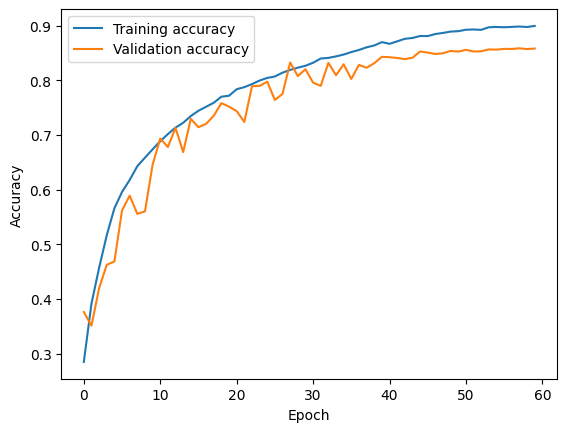

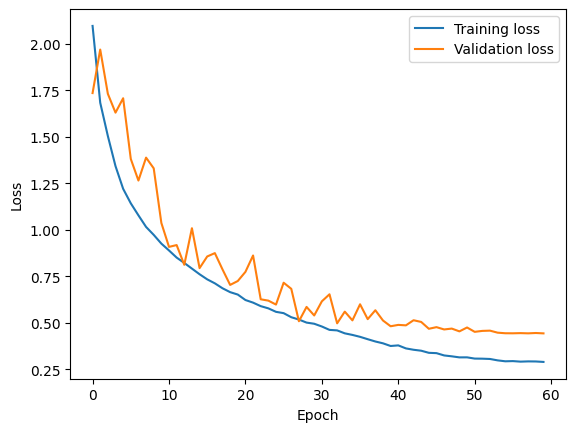

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Imports
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

#Check whether GPU is connected
print("GPUs:", tf.config.list_physical_devices('GPU'))

#Split data into training and validation (validate once per epoch)
x_train, y_train = x_full[:45000], y_full[:45000]
x_val, y_val = x_full[45000:], y_full[45000:]

#Fresh data for testing (Only test once at end)
x_test = np.stack([np.array(img) for img in ds["test"]["img"]]).astype("float32") / 255.0
y_test = np.array(ds["test"]["label"]).reshape(-1, 1)

#Constants
EPOCHS = 60
BATCH = 64

#Residual Block Function - residual learning mechanism
def res_block(x, filters): #Takes 2 parameters, x - inputs and filters-number of filters
    shortcut = x #Saves the original input, to resolve vanishing gradient problem - and bypass the conv layers later (during backpropogation).
    #First Convolution
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x) #Applies a 3x3 convolutional layer (kernel) to identify features or patterns
    x = layers.BatchNormalization()(x) #Normalises the activations so that each batch has similar distributions. This helps stabilise training and makes optimisation easier.
    x = layers.Activation('relu')(x) #Activation layer to allow for non-linearity. (Relu makes negative values 0, and leaves positives unchanged)
    #Second convolution - almost identical to the prior
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    if shortcut.shape[-1] != filters: #Checks whether the number of channels in input matches the number of filters in the conv layer.
        shortcut = layers.Conv2D(filters, 1, use_bias=False)(shortcut) #If not - fix the dimensions
    x = layers.Add()([x, shortcut]) #Adds the shortcut back onto the output.
    return layers.Activation('relu')(x) #Only normalises after adding the shortcut back onto the output. This reduces vanishing gradients by making backpropogation easier.

#Take the inputs
inputs = layers.Input((32, 32, 3))

#Apply augmentation every single epoch to avoid overfitting - where the model memorises the training datas pixels rather than patterns.
x = layers.RandomFlip('horizontal_and_vertical')(inputs)
x = layers.RandomTranslation(0.1, 0.1)(x)
x = layers.RandomRotation(0.2)(x)

x = res_block(x, 64)
x = res_block(x, 64)
x = layers.MaxPooling2D()(x)
x = layers.Dropout(0.1)(x)

x = res_block(x, 128)
x = res_block(x, 128)
x = layers.MaxPooling2D()(x)
x = layers.Dropout(0.2)(x)

x = res_block(x, 256)
x = res_block(x, 256)
x = layers.MaxPooling2D()(x)
x = layers.Dropout(0.3)(x)

x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10)(x)
model = models.Model(inputs, outputs)

steps_per_epoch = -(-len(x_train) // BATCH)   # 704
lr = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=3e-5,           # start really small
    decay_steps=(EPOCHS - 3) * steps_per_epoch,
    warmup_target=1e-3,                   # ramp it up to this during warmup
    warmup_steps=3 * steps_per_epoch)     # over 3 epochs it increases, then decreases using cosine-delay till the end.

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=lr,
        weight_decay=3e-4
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'])

history = model.fit(
    x_train, y_train, epochs=EPOCHS, batch_size=BATCH,
    validation_data=(x_val, y_val))

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"Test accuracy: {test_acc:.4f}")

model.save("my_cnn.keras")

h = history.history

plt.figure()
plt.plot(h["accuracy"], label="Training accuracy")
plt.plot(h["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.savefig("goat_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure()
plt.plot(h["loss"], label="Training loss")
plt.plot(h["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.savefig("goat_loss.png", dpi=300, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("goat_accuracy.png")
files.download("goat_loss.png")
files.download("my_cnn.keras")